In [40]:
import numpy as np
import matplotlib.pyplot as plt
from jinja2.compiler import has_safe_repr
from matplotlib.colors import ListedColormap
import random

class Maze:
    def __init__(self):
        self.grid = np.array([
            [0, 0, 0, 0, 0],
            [0, 0, 1, 0, 0],
            [2, 0, 1, 0, 3]
        ])

        self.start = (2, 0)
        self.goal = (2, 4)
        self.position = self.start

        self.actions = {
            "up": (-1, 0),
            "down": (1, 0),
            "left": (0, -1),
            "right": (0, 1)
        }

        # where 2 is start point and 3 is end point
        # and 1 is the wall
        # and 0 is the free space

    def reset(self):
        self.start = (2,0)
        return self.position

    def is_valid(self, position):
        row, col = position

        return (
            0 <= row < self.grid.shape[0]
            and 0 <= col < self.grid.shape[1]
            and self.grid[row, col] != 1
        )

    def step(self, action):
        if action not in self.actions:
            raise ValueError(f"Invalid action: {action}")

        dr, dc = self.actions[action]
        row, col = self.position

        new_state = (row + dr, col + dc)

        if not self.is_valid(new_state):
            return self.position, -2, False

        self.position = new_state

        if self.position == self.goal:
            return self.position, 0, True

        return self.position, -1, False



    def display(self):
        cmap = ListedColormap([
            "white",  # 0 = Empty
            "black",  # 1 = Wall
            "gold",   # 2 = Start
            "lime"    # 3 = Goal
        ])

        fig, ax = plt.subplots(figsize=(8, 5))

        ax.imshow(self.grid, cmap=cmap, vmin=0, vmax=3)

        # Draw agent at current position
        row, col = self.position
        ax.scatter(col, row, color="red", s=250, zorder=5)

        # Grid coordinates
        rows, cols = self.grid.shape

        ax.set_xticks(np.arange(cols))
        ax.set_yticks(np.arange(rows))

        # Grid borders
        ax.set_xticks(np.arange(-0.5, cols, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, rows, 1), minor=True)

        ax.grid(which="minor", color="black", linewidth=2)
        ax.tick_params(which="minor", bottom=False, left=False)

        ax.xaxis.tick_top()
        ax.set_title(f"Agent Position: {self.position}")

        plt.show()

In [71]:
class Agent:
    def __init__(self, maze):
        self.maze = maze
        self.episode_history = {} # stores each episode
        self.actions = ["up", "down", "left", "right"]
        self.gamma = 0.9

    def choose_action(self):
        return random.choice(self.actions)

    def generate_episode(self, max_steps=1000):
        # Reset maze to starting position
        self.maze.position = self.maze.start
        self.history = []

        state = self.maze.position

        for step in range(max_steps):
            # Choose an action
            action = self.choose_action()

            # Execute the action
            next_state, reward, done = self.maze.step(action)

            # Record transition
            self.history.append({
                "state": state,
                "action": action,
                "next_state": next_state,
                "reward": reward,
                "done": done
            })

            # Update current state
            state = next_state

            # Stop if goal reached
            if done:
                break

        # Automatically assign episode index
        episode_id = len(self.episode_history)

        # Store a separate copy of the episode
        self.episode_history[episode_id] = [
            move.copy() for move in self.history
        ]

        return self.history

    def calculate_path_rewards(self, episode_id):
        episode = self.episode_history[episode_id]
        value = 0.0

        for t, move in enumerate(reversed(episode)):
            value += (self.gamma ** t) * move["reward"]

        return value


    def calculate_state_rewards(self):
        # Store returns for each state
        state_returns = {}

        # Loop through all episodes
        for episode in self.episode_history.values():
            G = 0.0

            # Calculate discounted returns backwards
            for move in reversed(episode):
                G = move["reward"] + self.gamma * G

                state = move["state"]

                if state not in state_returns:
                    state_returns[state] = []

                state_returns[state].append(G)

        # Calculate average return for each state
        self.V = {}

        for state, returns in state_returns.items():
            self.V[state] = sum(returns) / len(returns)

        return self.V


    def calculate_action_rewards(self):
        action_returns = {}

        # Loop through all episodes
        for episode in self.episode_history.values():
            G = 0.0

            # Calculate discounted returns backwards
            for move in reversed(episode):
                G = move["reward"] + self.gamma * G

                state = move["state"]
                action = move["action"]

                key = (state, action)

                if key not in action_returns:
                    action_returns[key] = []

                action_returns[key].append(G)

        # Calculate average return for each state-action pair
        self.Q = {}

        for key, returns in action_returns.items():
            self.Q[key] = sum(returns) / len(returns)

        return self.Q

    def display_dashboard(self, episode_id=None, window=20):
        import matplotlib.pyplot as plt
        from matplotlib.colors import ListedColormap

        if not self.episode_history:
            raise ValueError("Generate episodes first.")

        if episode_id is None:
            episode_id = len(self.episode_history) - 1

        if episode_id not in self.episode_history:
            raise ValueError("Episode does not exist.")

        # Calculate Monte Carlo estimates
        self.calculate_state_rewards()
        self.calculate_action_rewards()

        episode = self.episode_history[episode_id]
        grid = self.maze.grid
        rows, cols = grid.shape

        cmap = ListedColormap([
            "white", "black", "gold", "lime"
        ])

        arrows = {
            "up": "↑",
            "down": "↓",
            "left": "←",
            "right": "→"
        }

        # Helper to draw the maze grid
        def draw_grid(ax, title, colored=True):
            if colored:
                ax.imshow(grid, cmap=cmap, vmin=0, vmax=3)
            else:
                ax.imshow(
                    np.zeros_like(grid),
                    cmap=ListedColormap(["white"]),
                    vmin=0,
                    vmax=1
                )

            ax.set_xticks(np.arange(cols))
            ax.set_yticks(np.arange(rows))
            ax.set_xticks(np.arange(-0.5, cols, 1), minor=True)
            ax.set_yticks(np.arange(-0.5, rows, 1), minor=True)

            ax.grid(which="minor", color="black", linewidth=1.5)
            ax.tick_params(which="minor", bottom=False, left=False)
            ax.xaxis.tick_top()
            ax.set_title(title, fontsize=13, pad=12)

        fig = plt.figure(figsize=(17, 9))
        gs = fig.add_gridspec(
            2, 3,
            height_ratios=[1, 0.85],
            hspace=0.45,
            wspace=0.3
        )

        fig.suptitle(
            "Monte Carlo",
            fontsize=26,
            color="red",
            fontweight="bold"
        )

        # ----------------------------------------
        # 1. Episode path
        # ----------------------------------------
        ax1 = fig.add_subplot(gs[0, 0])
        draw_grid(ax1, f"Episode {episode_id} Path")

        path = [episode[0]["state"]]
        path += [move["next_state"] for move in episode]

        path_rows = [s[0] for s in path]
        path_cols = [s[1] for s in path]

        ax1.plot(
            path_cols,
            path_rows,
            color="red",
            linewidth=2,
            alpha=0.75
        )

        # ----------------------------------------
        # 2. Greedy policy arrows
        # ----------------------------------------
        ax2 = fig.add_subplot(gs[0, 1])
        draw_grid(ax2, "Greedy Policy from Q-values")

        for r in range(rows):
            for c in range(cols):
                state = (r, c)

                if grid[r, c] == 1 or state == self.maze.goal:
                    continue

                # Only use observed Q-values
                q_values = {
                    action: self.Q[(state, action)]
                    for action in self.actions
                    if (state, action) in self.Q
                }

                if not q_values:
                    continue

                best_action = max(q_values, key=q_values.get)

                ax2.text(
                    c, r,
                    arrows[best_action],
                    ha="center",
                    va="center",
                    fontsize=28,
                    color="red",
                    fontweight="bold"
                )

        # ----------------------------------------
        # 3. Q-value table for every state
        # ----------------------------------------
        ax3 = fig.add_subplot(gs[0, 2])
        draw_grid(ax3, "Action Values Q(s,a)", colored=False)

        for r in range(rows):
            for c in range(cols):
                state = (r, c)

                if grid[r, c] == 1:
                    ax3.add_patch(
                        plt.Rectangle(
                            (c - 0.5, r - 0.5),
                            1, 1,
                            facecolor="black"
                        )
                    )
                    continue

                if state == self.maze.goal:
                    ax3.text(c, r, "GOAL",
                             ha="center", va="center",
                             fontsize=10, color="green")
                    continue

                values = [
                    self.Q.get((state, a))
                    for a in self.actions
                ]

                text = "\n".join(
                    f"{i}: {v:.2f}" if v is not None else f"{i}: --"
                    for i, v in enumerate(values)
                )

                ax3.text(
                    c, r, text,
                    ha="center",
                    va="center",
                    fontsize=8,
                    family="monospace"
                )

        # ----------------------------------------
        # 4. Episode statistics
        # ----------------------------------------
        ax4 = fig.add_subplot(gs[1, :2])
        ax4.axis("off")

        total_reward = sum(m["reward"] for m in episode)
        discounted_return = self.calculate_path_rewards(episode_id)
        steps = len(episode)
        reached_goal = episode[-1]["done"]

        stats = (
            f"Episode: {episode_id}\n\n"
            f"Policy: Uniform Random (25% per action)\n\n"
            f"Total reward: {total_reward:.2f}\n\n"
            f"Discounted return: {discounted_return:.2f}\n\n"
            f"Steps: {steps}\n\n"
            f"Goal reached: {reached_goal}"
        )

        ax4.text(
            0.05, 0.95,
            stats,
            transform=ax4.transAxes,
            fontsize=14,
            va="top"
        )

        # ----------------------------------------
        # 5. Average episode reward
        # ----------------------------------------
        ax5 = fig.add_subplot(gs[1, 2])

        rewards = [
            sum(move["reward"] for move in ep)
            for ep in self.episode_history.values()
        ]

        x = np.arange(len(rewards))

        ax5.plot(
            x,
            rewards,
            alpha=0.25,
            label="Episode reward"
        )

        if len(rewards) >= window:
            moving_average = np.convolve(
                rewards,
                np.ones(window) / window,
                mode="valid"
            )

            ax5.plot(
                np.arange(window - 1, len(rewards)),
                moving_average,
                color="red",
                linewidth=2,
                label=f"{window}-episode average"
            )

        ax5.axvline(
            episode_id,
            color="black",
            linestyle="--",
            alpha=0.5
        )

        ax5.set_title("Average Total Reward")
        ax5.set_xlabel("Episode")
        ax5.set_ylabel("Total reward")
        ax5.grid(alpha=0.25)
        ax5.legend(fontsize=9)

        plt.show()
        plt.close(fig)


    def display_q_values(self):
        import matplotlib.pyplot as plt
        import numpy as np

        self.calculate_action_rewards()

        rows, cols = self.maze.grid.shape

        fig, ax = plt.subplots(figsize=(16, 9))

        ax.set_facecolor("white")
        fig.patch.set_facecolor("white")

        ax.set_xlim(-0.5, cols - 0.5)
        ax.set_ylim(rows - 0.5, -0.5)
        ax.set_aspect("equal")

        for x in np.arange(-0.5, cols + 0.5, 1):
            ax.axvline(x, color="black", linewidth=2)

        for y in np.arange(-0.5, rows + 0.5, 1):
            ax.axhline(y, color="black", linewidth=2)

        for row in range(rows):
            for col in range(cols):
                state = (row, col)

                if self.maze.grid[row, col] == 1:
                    ax.add_patch(
                        plt.Rectangle(
                            (col - 0.5, row - 0.5),
                            1, 1,
                            facecolor="#DDDDDD"
                        )
                    )
                    continue

                if state == self.maze.goal:
                    ax.text(
                        col, row, "GOAL",
                        ha="center", va="center",
                        fontsize=13,
                        color="green",
                        fontweight="bold"
                    )
                    continue

                lines = []

                for action in self.actions:
                    value = self.Q.get((state, action))

                    if value is None:
                        lines.append(f"{action}: --")
                    else:
                        lines.append(f"{action}: {value:6.2f}")

                text = "\n".join(lines)

                ax.text(
                    col, row,
                    text,
                    ha="center",
                    va="center",
                    fontsize=10,
                    color="black",
                    family="monospace",
                    linespacing=1.3
                )

        ax.set_xticks(range(cols))
        ax.set_yticks(range(rows))
        ax.xaxis.tick_top()
        ax.tick_params(axis="both", length=0, labelsize=13)

        ax.set_title(
            "Monte Carlo Action-Value Function Q(s,a)",
            fontsize=19,
            fontweight="bold",
            pad=30
        )

        plt.tight_layout()
        plt.show()



In [72]:
maze = Maze()

In [73]:
agent = Agent(maze)

In [74]:
for i in range(100):
    agent.generate_episode(max_steps=1000)

In [75]:
agent.calculate_action_rewards()

{((1, 4), 'down'): 0.0,
 ((0, 4), 'down'): -7.156889761624383,
 ((0, 3), 'right'): -10.47022193169399,
 ((0, 3), 'up'): -11.382670637421363,
 ((0, 4), 'left'): -11.379766823542033,
 ((0, 4), 'right'): -11.741708219329551,
 ((1, 4), 'up'): -9.67643591584024,
 ((1, 4), 'right'): -7.65574776178106,
 ((1, 3), 'right'): -7.588529823340126,
 ((0, 3), 'down'): -8.353299885214936,
 ((0, 2), 'right'): -10.11769072611887,
 ((0, 2), 'up'): -12.949858786544917,
 ((0, 3), 'left'): -11.95084692261653,
 ((0, 1), 'right'): -11.887527126819982,
 ((0, 1), 'up'): -13.656159306276606,
 ((0, 0), 'right'): -12.696685336904089,
 ((1, 0), 'up'): -13.162605591303134,
 ((2, 0), 'up'): -13.135091072649745,
 ((2, 0), 'down'): -14.565405898143037,
 ((2, 0), 'left'): -14.531893649634673,
 ((1, 0), 'down'): -13.484521064217333,
 ((2, 1), 'left'): -13.4558131285314,
 ((2, 1), 'down'): -14.406852328092283,
 ((1, 1), 'down'): -13.460456151022921,
 ((2, 1), 'up'): -12.915449043074622,
 ((2, 1), 'right'): -14.40768803273

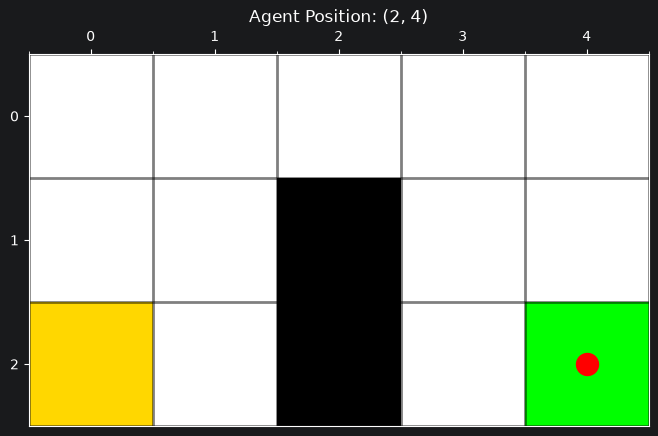

In [76]:
maze.display()

In [77]:
from ipywidgets import interact, IntSlider

interact(
    agent.display_dashboard,
    episode_id=IntSlider(
        min=0,
        max=len(agent.episode_history) - 1,
        step=1,
        value=0,
        description="Episode"
    ),
    window=20
)

interactive(children=(IntSlider(value=0, description='Episode', max=99), IntSlider(value=20, description='wind…

<function ipywidgets.widgets.interaction._InteractFactory.__call__.<locals>.<lambda>(*args, **kwargs)>

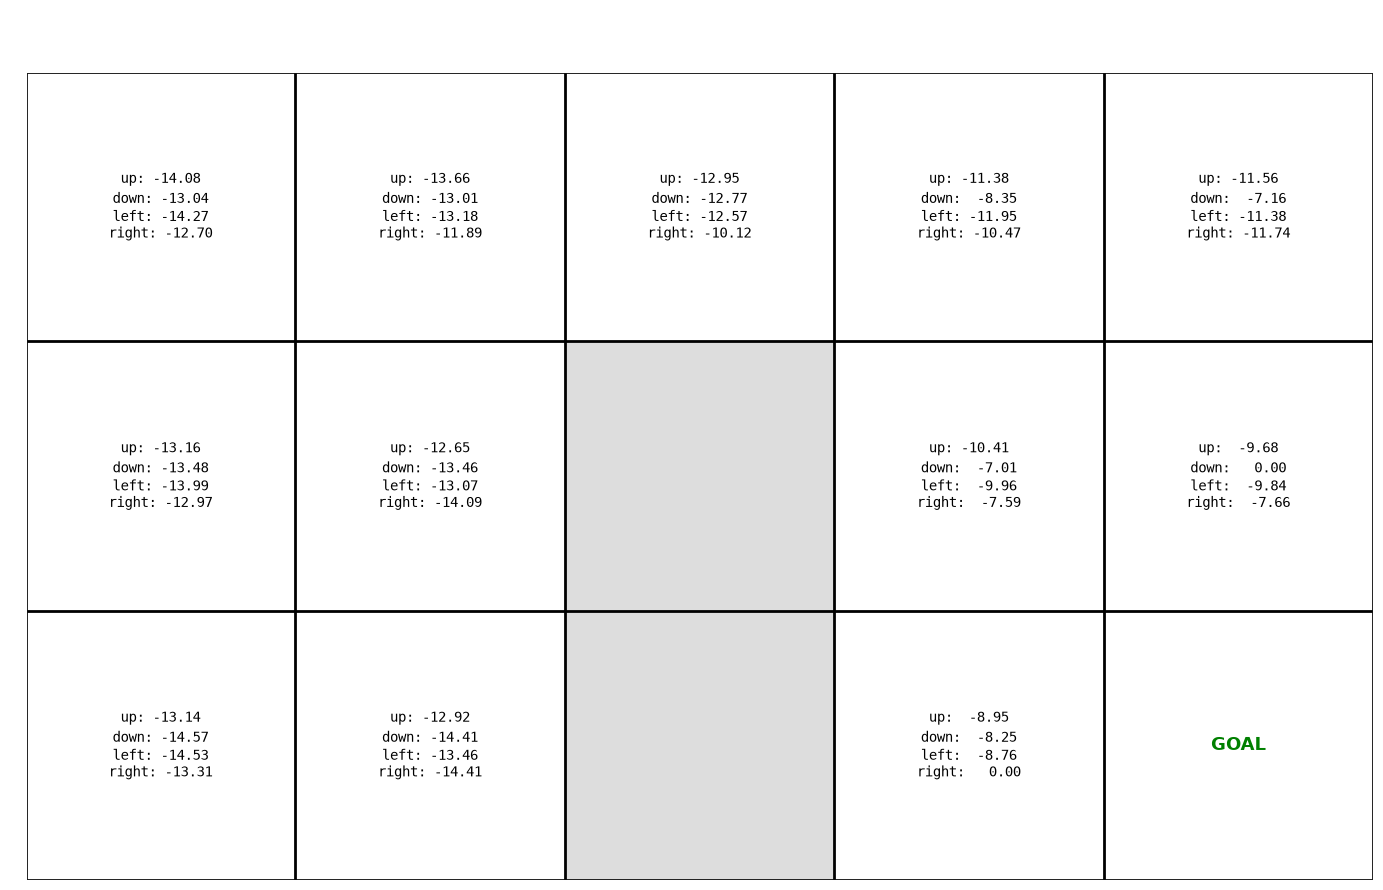

In [78]:
agent.display_q_values()